<a href="https://colab.research.google.com/github/MUKESHKUMAR-21/FDVA/blob/main/FDVA_End_Semester_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FDVA End Semester Project
An end-to-end interactive dashboard demonstrating data cleaning, preprocessing, normalization, and visualization on credit application data.

Output()

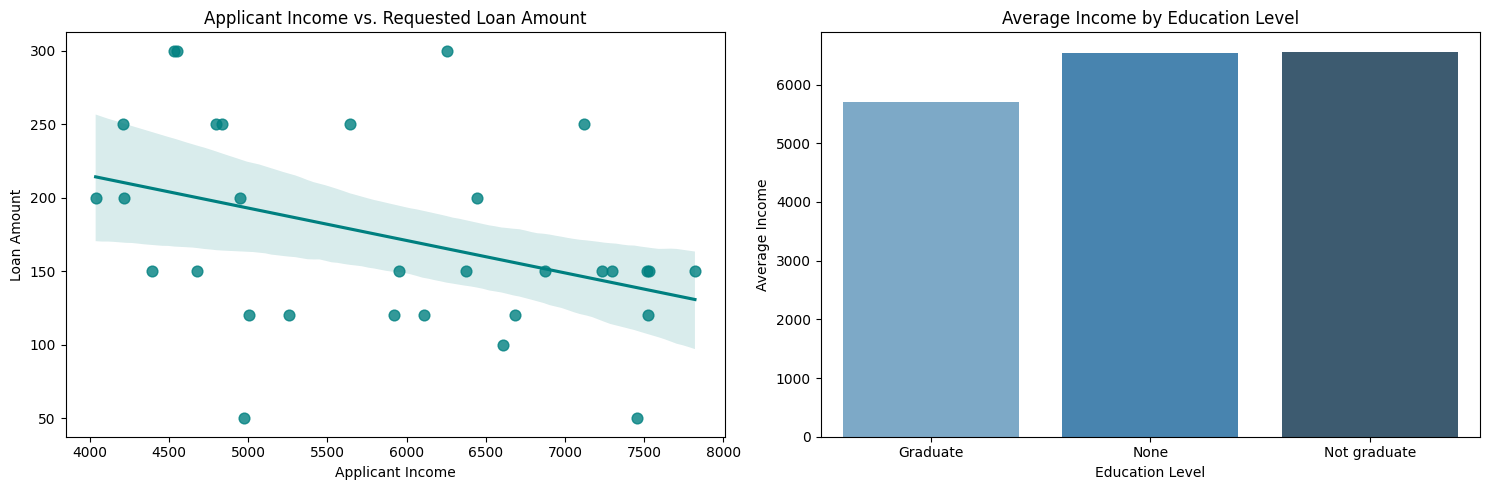

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
import ipywidgets as widgets
from IPython.display import display

# =========================================================
# STEP 1: FINANCIAL DATASET SIMULATION
# =========================================================
np.random.seed(42)
n_samples = 150

data = {
    'Gender': np.random.choice(['Male', 'Female', None], size=n_samples, p=[0.7, 0.25, 0.05]),
    'Married': np.random.choice(['Yes', 'No', None], size=n_samples, p=[0.6, 0.35, 0.05]),
    'Dependents': np.random.choice(['0', '1', '2', '3+', None], size=n_samples, p=[0.5, 0.2, 0.15, 0.1, 0.05]),
    'Education': np.random.choice(['Graduate', 'Not Graduate', None], size=n_samples, p=[0.75, 0.2, 0.05]),
    'Self_Employed': np.random.choice(['Yes', 'No', None], size=n_samples, p=[0.12, 0.8, 0.08]),
    'ApplicantIncome': np.random.randint(1500, 10000, size=n_samples),
    'CoapplicantIncome': np.random.randint(0, 5000, size=n_samples),
    'LoanAmount': np.random.choice([np.nan, 50, 100, 120, 150, 200, 250, 300], size=n_samples, p=[0.1, 0.1, 0.15, 0.15, 0.2, 0.15, 0.1, 0.05]),
    'Loan_Amount_Term': np.random.choice([360, 180, 240, 120, None], size=n_samples, p=[0.8, 0.08, 0.05, 0.02, 0.05]),
    'Credit_History': np.random.choice([1.0, 0.0, None], size=n_samples, p=[0.8, 0.15, 0.05]),
    'Property_Area': np.random.choice(['Urban', 'Semiurban', 'Rural'], size=n_samples)
}

df = pd.DataFrame(data)
# Inject mock duplicate rows to demonstrate clean-up
df = pd.concat([df, df.iloc[:5]], ignore_index=True)

# =========================================================
# STEP 2: DATA PREPROCESSING & CLEANING
# =========================================================
# Imputation
for col in ['Gender', 'Married', 'Dependents', 'Self_Employed']:
    df[col] = df[col].fillna(df[col].mode()[0])

df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].mode()[0])
df['Credit_History'] = df['Credit_History'].fillna(df['Credit_History'].mode()[0])

# Removing Duplicates
df.drop_duplicates(inplace=True)

# Dependents Conversion
df['Dependents'] = df['Dependents'].replace('3+', 3).fillna(0).astype(int)

# Uniform String Casing
for col in ['Gender', 'Married', 'Education', 'Self_Employed', 'Property_Area']:
    df[col] = df[col].astype(str).str.strip().str.capitalize()

# Min-Max Normalization
min_max_scaler = MinMaxScaler()
scale_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']
df_scaled = df.copy()
df_scaled[scale_cols] = min_max_scaler.fit_transform(df[scale_cols])

# =========================================================
# STEP 3: DATA VISUALIZATION AND INTERACTIVE WIDGETS
# =========================================================
income_slider = widgets.IntRangeSlider(
    value=[2000, 8000],
    min=1500,
    max=10000,
    step=500,
    description='Income Range:',
    style={'description_width': 'initial'}
)

property_dropdown = widgets.Dropdown(
    options=['All', 'Urban', 'Semiurban', 'Rural'],
    value='All',
    description='Property Location:',
    style={'description_width': 'initial'}
)

ui = widgets.HBox([income_slider, property_dropdown])

def update_dashboard(income_range, location):
    filtered_df = df[(df['ApplicantIncome'] >= income_range[0]) & (df['ApplicantIncome'] <= income_range[1])]
    if location != 'All':
        filtered_df = filtered_df[filtered_df['Property_Area'] == location]

    print(f"--- Showing {len(filtered_df)} Matching Credit Records ---")

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Plot 1: Income vs Loan Amount scatter with Trend line
    sns.regplot(data=filtered_df, x='ApplicantIncome', y='LoanAmount', ax=axes[0], color='teal', scatter_kws={'s': 60})
    axes[0].set_title("Applicant Income vs. Requested Loan Amount")
    axes[0].set_xlabel("Applicant Income")
    axes[0].set_ylabel("Loan Amount")

    # Plot 2: Education Level vs average income distribution
    sns.barplot(data=filtered_df, x='Education', y='ApplicantIncome', ax=axes[1], palette='Blues_d', errorbar=None)
    axes[1].set_title("Average Income by Education Level")
    axes[1].set_xlabel("Education Level")
    axes[1].set_ylabel("Average Income")

    plt.tight_layout()
    plt.show()

out = widgets.interactive_output(update_dashboard, {'income_range': income_slider, 'location': property_dropdown})
display(ui, out)